# Week 3 - Monday: K-Means, Elbow Method and Silhouette Score
Dataset: `Mall_Customers.csv` (200 rows). Features used for clustering: **Annual Income (k$)** and **Spending Score (1-100)**.

Clustering is **unsupervised**: no labels, no accuracy. We judge results with the Elbow method, the Silhouette score, and whether the clusters make sense to a human.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the data
Upload `Mall_Customers.csv` to Colab (Files panel > Upload), or run the cell below and pick the file.

In [2]:
import os
if not os.path.exists("Mall_Customers.csv"):
    try:
        from google.colab import files
        files.upload()   # choose Mall_Customers.csv
    except ImportError:
        raise FileNotFoundError("Put Mall_Customers.csv next to this notebook.")

df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Gender": "Genre"})
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. EDA

In [3]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
df.describe()

Shape: (200, 5)

Missing values:
 CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Genre
Female    112
Male       88
Name: count, dtype: int64


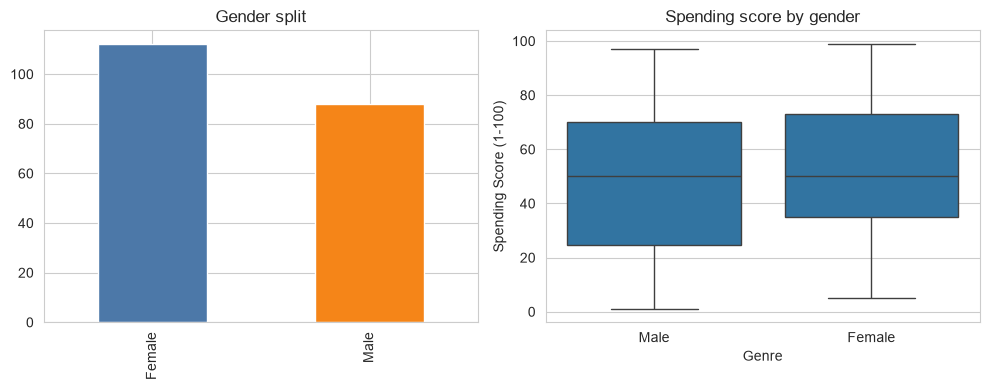

In [4]:
print(df["Genre"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["Genre"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("Gender split")
axes[0].set_xlabel("")
sns.boxplot(data=df, x="Genre", y="Spending Score (1-100)", ax=axes[1])
axes[1].set_title("Spending score by gender")
plt.tight_layout(); plt.show()

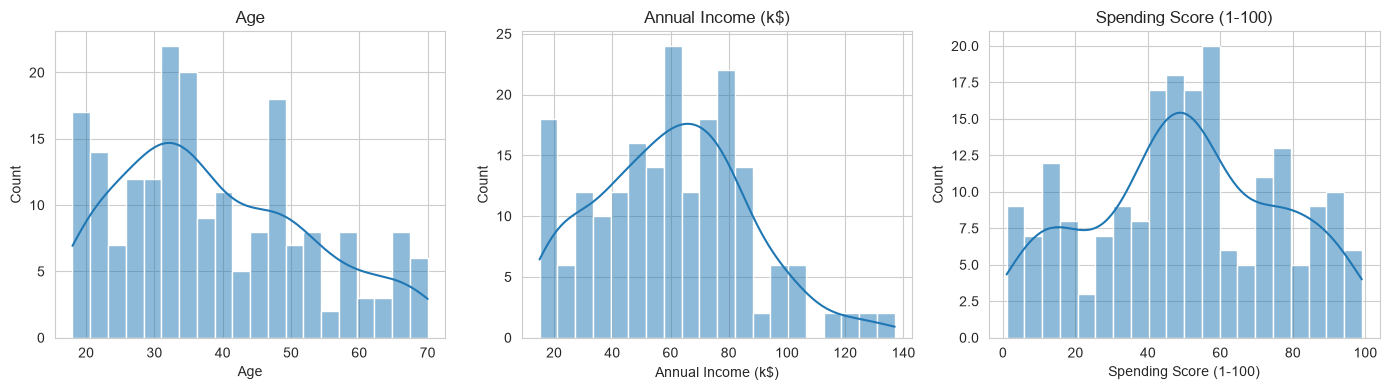

In [5]:
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c], bins=20, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

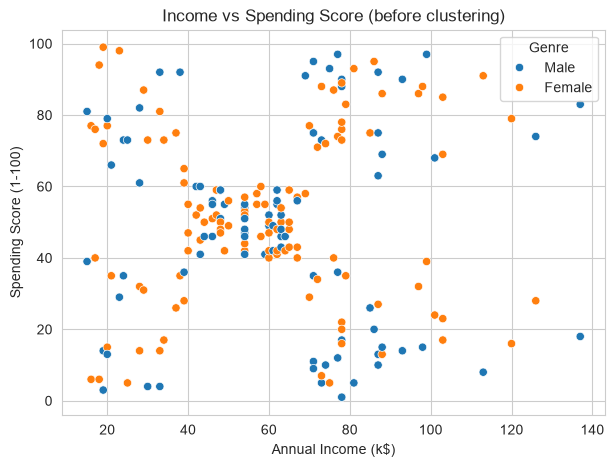

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Genre")
plt.title("Income vs Spending Score (before clustering)")
plt.show()

**Look at the scatter plot first.** Before running any algorithm, how many groups do *you* see? Write your guess in the notes at the end, then compare with what the Elbow and Silhouette say.

## 4. Select features and scale
K-Means uses distances, so features must be on the same scale.

In [7]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling :", X_scaled.std(axis=0).round(3))

Mean after scaling: [-0. -0.]
Std after scaling : [1. 1.]


## 5. Elbow method and Silhouette score (k = 2 to 10)

In [8]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({"k": list(k_range), "inertia": inertias, "silhouette": sil_scores})
results

,k,inertia,silhouette
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.228188,0.455215
7,9,32.392268,0.457085
8,10,29.981898,0.443171


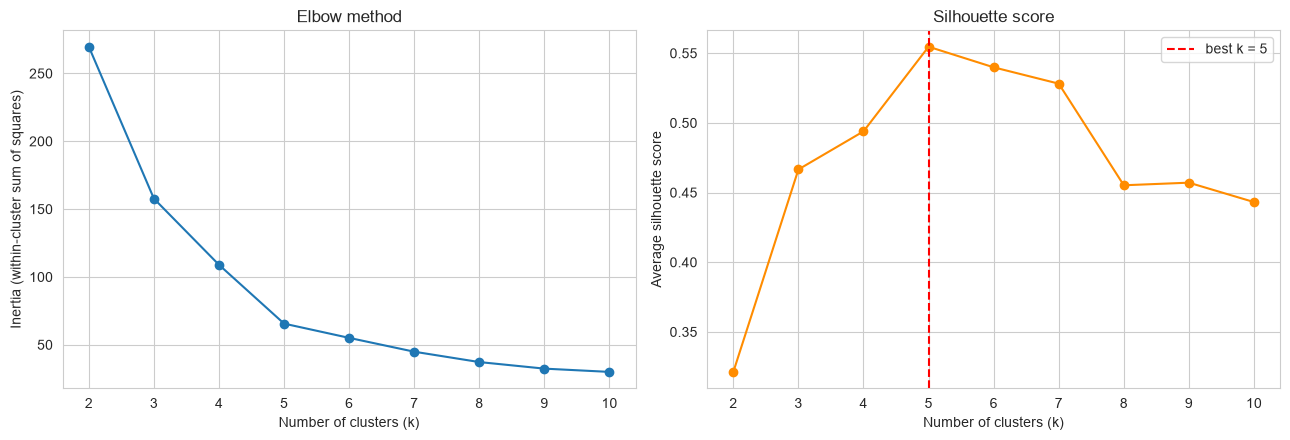

k with highest silhouette: 5


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results["k"], results["inertia"], "o-")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

axes[1].plot(results["k"], results["silhouette"], "o-", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")

best_k = int(results.loc[results["silhouette"].idxmax(), "k"])
axes[1].axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
axes[1].legend()

plt.tight_layout(); plt.show()
print("k with highest silhouette:", best_k)

**How to read these:**
- **Elbow:** inertia always falls as k grows. Look for the k where the drop flattens out (the bend).
- **Silhouette:** closer to 1 is better. The peak suggests the k with the tightest, best-separated clusters.
- They can disagree. Elbow is a visual judgement; silhouette gives a number. Use both, plus common sense about what the clusters mean.

## 6. Silhouette plot per cluster (optional but useful)

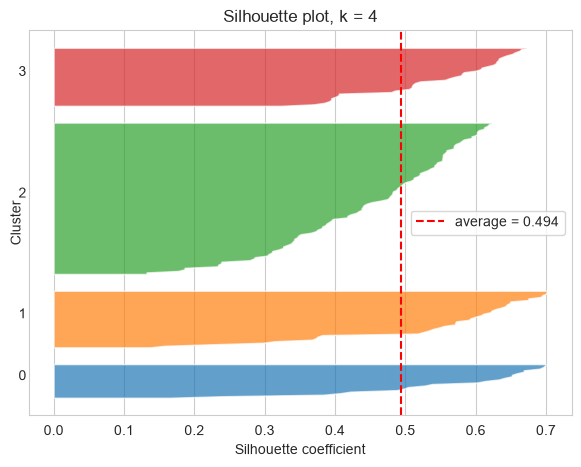

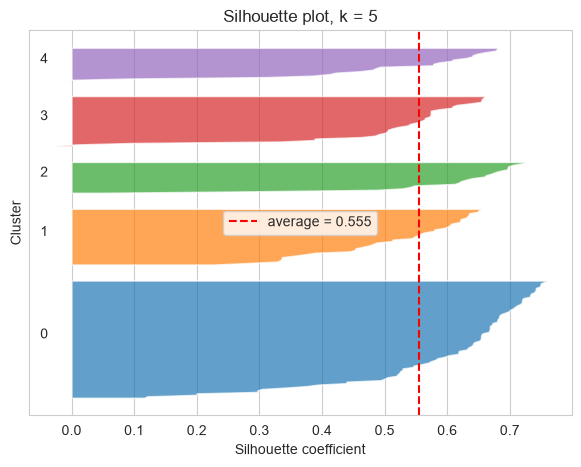

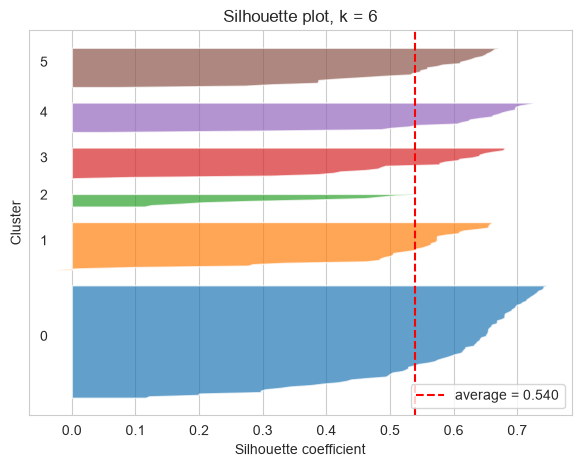

In [10]:
def silhouette_plot(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    sample_sil = silhouette_samples(X_scaled, labels)
    avg = silhouette_score(X_scaled, labels)

    plt.figure(figsize=(7, 5))
    y_lower = 10
    for i in range(k):
        vals = np.sort(sample_sil[labels == i])
        y_upper = y_lower + len(vals)
        plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7)
        plt.text(-0.05, y_lower + 0.5 * len(vals), str(i))
        y_lower = y_upper + 10
    plt.axvline(avg, color="red", linestyle="--", label=f"average = {avg:.3f}")
    plt.title(f"Silhouette plot, k = {k}")
    plt.xlabel("Silhouette coefficient"); plt.ylabel("Cluster")
    plt.yticks([]); plt.legend(); plt.show()

for k in [4, 5, 6]:
    silhouette_plot(k)

Good clusters have bars that reach past the red average line and are similar in width. A cluster with many values below the line, or a very thin or very wide one, is a warning sign.

## 7. Final model
Set `FINAL_K` to the value you choose after looking at both plots. For this dataset the classic answer is 5.

In [11]:
FINAL_K = 5

kmeans = KMeans(n_clusters=FINAL_K, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Silhouette score:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
print("Inertia:", round(kmeans.inertia_, 2))
print("\nCluster sizes:\n", df["Cluster"].value_counts().sort_index())

Silhouette score: 0.5547
Inertia: 65.57

Cluster sizes:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


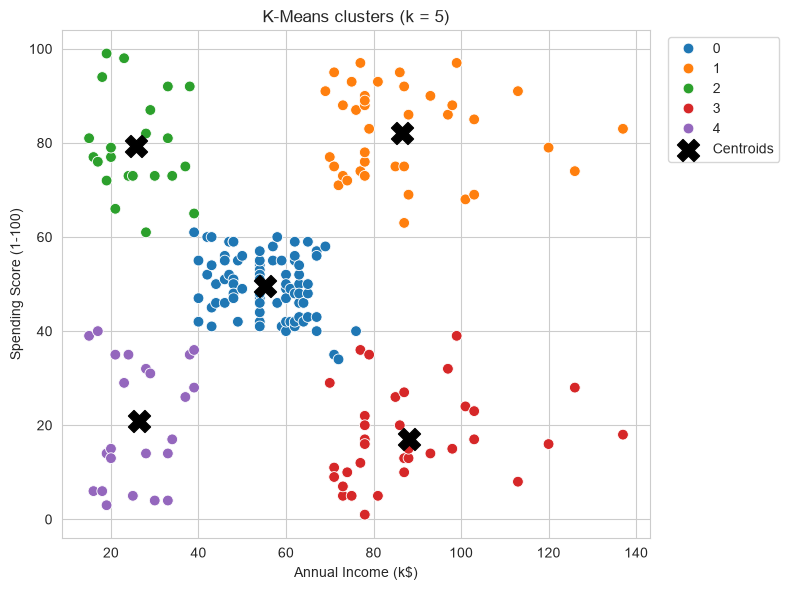

In [12]:
# Centroids are in scaled space, convert back to original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=60)
plt.scatter(centroids[:, 0], centroids[:, 1], c="black", marker="X", s=250, label="Centroids")
plt.title(f"K-Means clusters (k = {FINAL_K})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 8. Describe each cluster in words

In [13]:
profile = df.groupby("Cluster").agg(
    customers=("CustomerID", "count"),
    avg_age=("Age", "mean"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean"),
    pct_female=("Genre", lambda s: (s == "Female").mean() * 100),
).round(1)
profile

,customers,avg_age,avg_income,avg_spending,pct_female
Cluster,,,,,
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
2,22,25.3,25.7,79.4,59.1
3,35,41.1,88.2,17.1,45.7
4,23,45.2,26.3,20.9,60.9


In [14]:
def label_cluster(row):
    high_inc = row["avg_income"] >= 60
    high_spend = row["avg_spending"] >= 60
    if high_inc and high_spend:   return "High income, high spending (target)"
    if high_inc and not high_spend: return "High income, low spending (careful)"
    if not high_inc and high_spend: return "Low income, high spending (impulsive)"
    if row["avg_income"] < 40 and row["avg_spending"] < 40: return "Low income, low spending (sensible)"
    return "Mid income, mid spending (standard)"

profile["suggested_label"] = profile.apply(label_cluster, axis=1)
profile

,customers,avg_age,avg_income,avg_spending,pct_female,suggested_label
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,"Mid income, mid spending (standard)"
1,39,32.7,86.5,82.1,53.8,"High income, high spending (target)"
2,22,25.3,25.7,79.4,59.1,"Low income, high spending (impulsive)"
3,35,41.1,88.2,17.1,45.7,"High income, low spending (careful)"
4,23,45.2,26.3,20.9,60.9,"Low income, low spending (sensible)"


These labels are a starting point from simple thresholds. Rename them in your own words after looking at the scatter plot.

## 9. Bonus: does adding Age change things?

In [15]:
X3 = StandardScaler().fit_transform(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]])
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X3)
    print(f"k={k}  silhouette={silhouette_score(X3, labels):.3f}")

k=2  silhouette=0.335
k=3  silhouette=0.358
k=4  silhouette=0.404
k=5  silhouette=0.417
k=6  silhouette=0.428
k=7  silhouette=0.417
k=8  silhouette=0.408
